# Superstore Dataset

## Step 1:Import necessary libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

## Step 2:Import dataset

In [2]:
superstore_data = pd.read_csv("Sample - Superstore.csv",encoding="latin1")
superstore_data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
pd.set_option('display.max_columns', None)

## Step 3:Initial Analysis

In [4]:
superstore_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [5]:
superstore_data.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [6]:
superstore_data.isna().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
superstore_data.duplicated().sum()

np.int64(0)

## Step 4:Data prepuration

In [8]:
# Convert column to datetime
superstore_data["Order Date"] = pd.to_datetime(superstore_data["Order Date"])
superstore_data.dtypes

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date                object
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [9]:
#Extract the year
superstore_data["year"] = superstore_data["Order Date"].dt.year

## step 5:Data visuvalization

# 5.1 Univariant chat

## 5.1.1:Year-over-Year Profit Analysis (2014–2017)

In [11]:
superstore_data.groupby("year")["Profit"].mean()

year
2014    24.858994
2015    29.314274
2016    31.617771
2017    28.212340
Name: Profit, dtype: float64

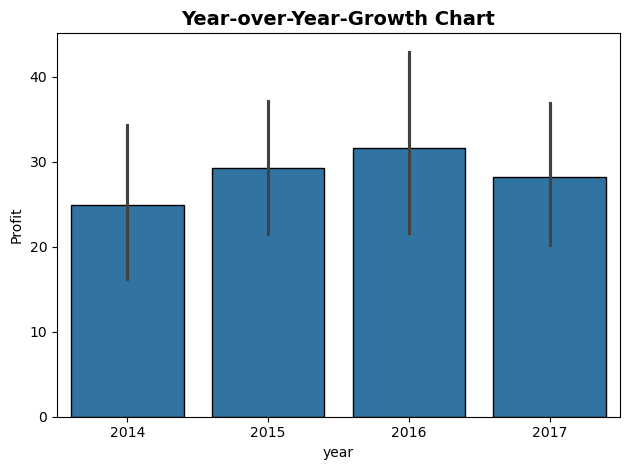

In [12]:
sns.barplot(data=superstore_data,x= "year",y="Profit",edgecolor="black")
plt.title("Year-over-Year-Growth Chart",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.savefig("Year-over-Year Profit Analysis", dpi=150)
plt.show()


### Slide Title

### Key Insights: Year-over-Year Profit Analysis (2014–2017)

### Key Insights
* 📈 The dataset contains four years (2014–2017) of profit data.
* 🚀 Average profit increased steadily from 2014 to 2016, indicating consistent business growth.
* 🏆 2016 recorded the highest average profit, making it the best-performing year.
* 📉 Profit declined slightly in 2017 compared to 2016, suggesting a slowdown in growth.
*📊 The error bars indicate that profit varied across different orders each year, with 2016 showing the greatest variation.

### Business Recommendation

* Analyze the factors that contributed to the strong performance in 2016 and identify the reasons for the decline in 2017 to improve future profitability.

### Presentation Script (30 seconds)

* "This chart shows the average profit from 2014 to 2017. We can see that profit increased consistently from 2014 to 2016, with 2016 being the best-performing year. In 2017, profit decreased slightly compared to 2016. The error bars show that profit varied across different transactions. Based on this analysis, the company should study the successful strategies used in 2016 and address the factors that caused the decline in 2017."

## 5.1.2:Superstore Sales by Category

In [151]:
sales_by_category = superstore_data.groupby(by="Category")["Sales"].sum().sort_values(ascending=False)
sales_by_category

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

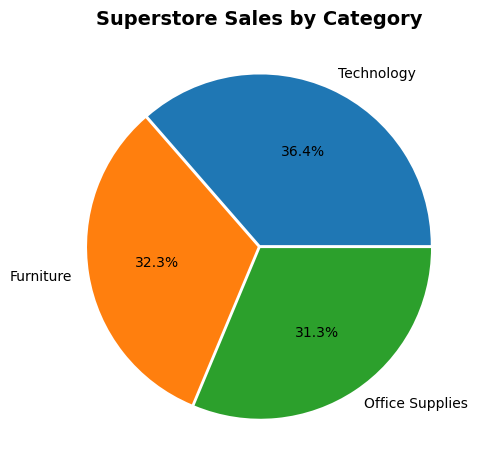

In [152]:
plt.pie(sales_by_category,labels=sales_by_category.index,explode=[0.01,0.01,0.01],autopct="%1.1f%%"
       )
plt.title("Superstore Sales by Category",fontsize=14,fontweight="bold")

plt.tight_layout()
plt.savefig("Superstore Sales by Category", dpi=150)
plt.show()


### For a professional presentation, keep the insights short and business-focused.

### Key Insights – Superstore Sales by Category
* Technology is the highest revenue-generating category, contributing 36.4% of total sales.
* Furniture accounts for 32.3% of total sales, making it the second-largest sales category.
* Office Supplies contributes 31.3%, representing the smallest share among the three categories.
* The sales distribution is well-balanced, with each category contributing around one-third of total sales.
* Since Technology leads sales, it presents the greatest opportunity for revenue growth through continued investment in inventory, promotions, and marketing.

### Slide Content (Professional)

### Key Insights

* 📈 Technology generated the highest sales (36.4%).
* 🪑 Furniture contributed 32.3% of total sales.
* 📝 Office Supplies accounted for 31.3% of total sales.
* ⚖️ Sales are evenly distributed across all three product categories.
* 💡 Technology is the primary revenue driver and should remain a strategic focus for business growth.

###Presentation Tip (1 sentence):

"Technology is the top-performing category with 36.4% of total sales, while Furniture and Office Supplies contribute nearly equal shares, indicating a well-diversified sales portfolio."

## 5.1.3:Distribution of Order Quantity

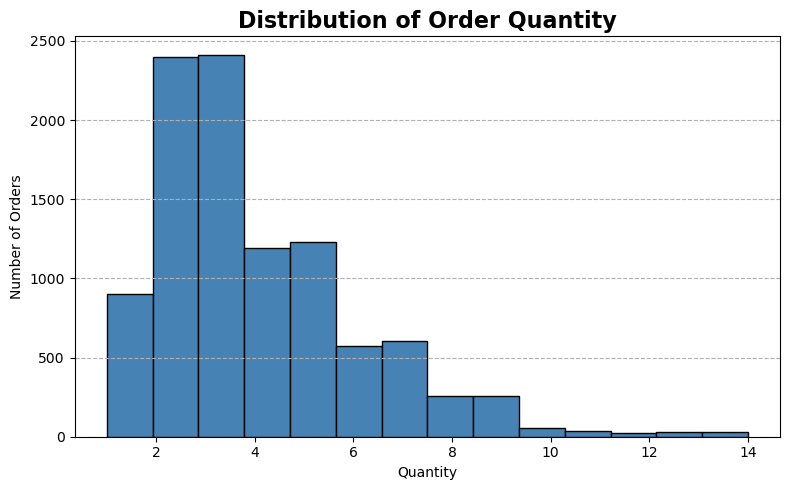

In [153]:
plt.figure(figsize=(8,5))
plt.hist(superstore_data["Quantity"],bins=14,color="steelblue",edgecolor="black")

plt.title("Distribution of Order Quantity",fontsize=16,fontweight="bold")
plt.xlabel("Quantity")
plt.ylabel("Number of Orders")

plt.grid(axis="y", linestyle="--")

plt.tight_layout()
plt.savefig("Distribution of Order Quantity", dpi=150)
plt.show()


### For your PowerPoint, use concise, business-oriented insights.

### Key Insights – Distribution of Order Quantity
* Most orders contain 2–4 items, indicating customers typically purchase in small quantities.
* The distribution is positively (right) skewed, with order frequency decreasing as quantity increases.
* High-quantity orders (10–14 items) are rare, representing only a small portion of total orders.
* The majority of sales volume comes from low- to medium-quantity purchases, highlighting frequent small transactions.
* Businesses can increase average order value by encouraging customers to purchase more items through bundle offers or quantity-based discounts.
### Slide Content (Professional)
### Key Insights
* 📦 Most customers order 2–4 items per transaction.
* 📉 Order frequency declines as the order quantity increases.
* 📊 The distribution is right-skewed, with very few large orders.
* 🛒 Small and medium-sized purchases dominate customer buying behavior.
* 💡 Bundle deals and quantity discounts could encourage higher-value orders.

### Presentation Script (30 seconds)

* "This histogram shows that most customers purchase between 2 and 4 items per order. As the order quantity increases, the number of orders decreases significantly, resulting in a right-skewed distribution. Large orders are uncommon, suggesting that customers generally prefer smaller purchases. To increase revenue, the business can introduce bundle offers or quantity-based discounts to encourage customers to buy more items per transaction."

## 5.1.4:Oreder Count by Sub-Category

In [154]:
order = superstore_data["Sub-Category"].value_counts().index

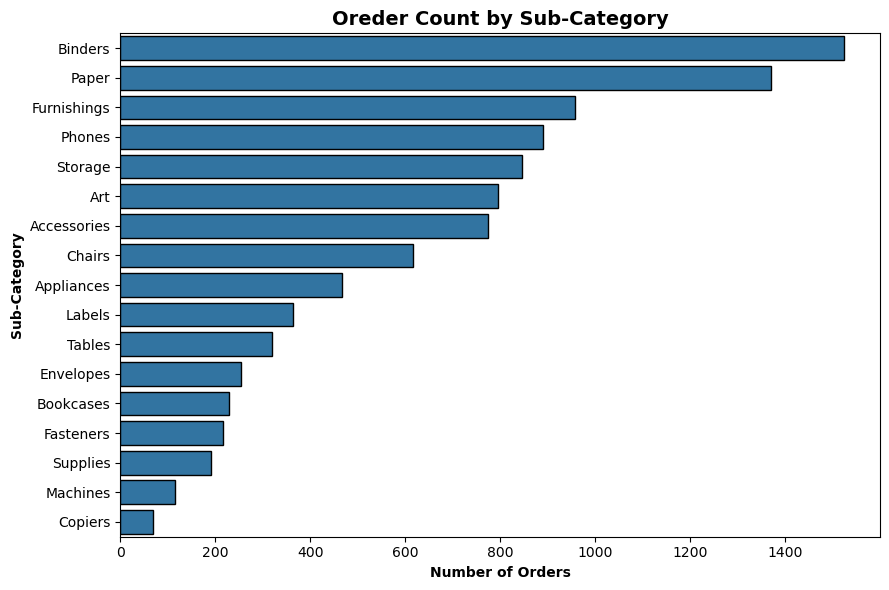

In [155]:
plt.figure(figsize=(9,6))
sns.countplot(data = superstore_data,y="Sub-Category",order=order,edgecolor="black")

plt.title("Oreder Count by Sub-Category",fontsize=14,fontweight="bold")
plt.xlabel("Number of Orders",fontweight="bold")
plt.ylabel("Sub-Category",fontweight="bold")

plt.tight_layout()
plt.savefig("Oreder Count by Sub-Category", dpi=150)
plt.show()


### For a professional PowerPoint presentation, focus on the business implications rather than just describing the chart.

### Key Insights – Order Count by Sub-Category
* Binders received the highest number of orders, making it the most frequently purchased sub-category.
* Paper ranks second, indicating strong and consistent demand for office-related products.
* Furnishings, Phones, and Storage also show high order volumes, reflecting steady customer demand.
* Copiers, Machines, and Supplies have the lowest order counts, suggesting lower demand or more specialized purchases.
* The business should maintain inventory for high-demand products while reviewing marketing and pricing strategies for low-performing sub-categories.
### Slide Content (Professional)
### Key Insights
* 📦 Binders recorded the highest number of orders.
* 📄 Paper is the second most frequently ordered sub-category.
* 📈 Furnishings, Phones, and Storage show consistently strong customer demand.
* 📉 Copiers and Machines have the lowest order frequency.
* 💡 Optimize inventory for high-demand products and improve sales strategies for low-demand sub-categories.

### Presentation Script (30 seconds)

"This chart shows the number of orders across different product sub-categories. Binders lead with the highest order count, followed by Paper, highlighting strong demand for office supplies. Furnishings, Phones, and Storage also contribute significantly to total orders. On the other hand, Copiers and Machines have relatively low order volumes, indicating niche demand or higher-priced products. These insights can help optimize inventory planning and guide targeted marketing strategies."

# 5.2 Bivariate

## 5.2.1 Diacount vs Profit

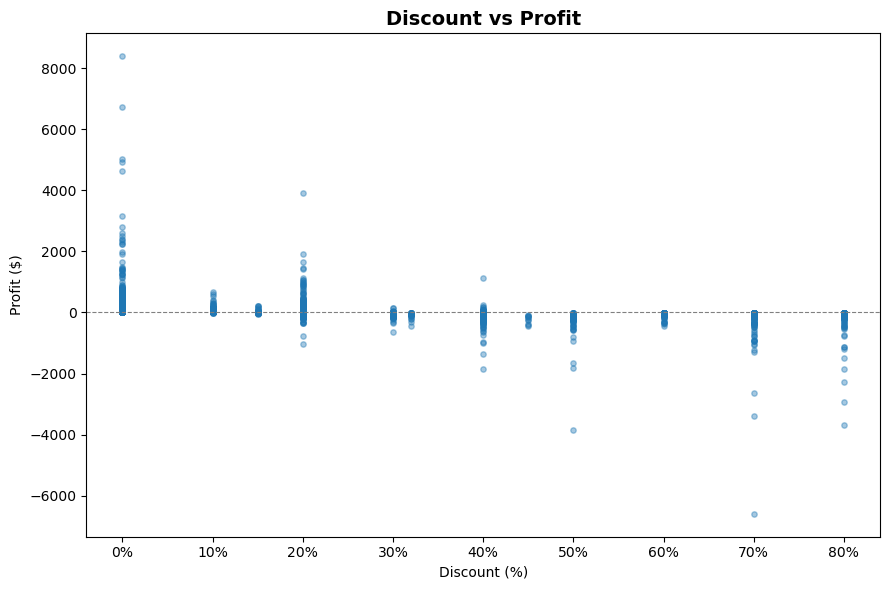

In [156]:
plt.figure(figsize = (9,6))
plt.scatter(data=superstore_data,x="Discount",y="Profit",alpha=0.4,s=15)
plt.axhline(0,color="gray",linewidth=0.8,linestyle="--")

plt.gca().xaxis.set_major_formatter(PercentFormatter(xmax=1))  # xmax=1 because Discount is stored as 0.0-1.0

plt.title("Discount vs Profit",fontsize=14,fontweight="bold")
plt.xlabel("Discount (%)")
plt.ylabel("Profit ($)")

plt.tight_layout()
plt.savefig("Diacount vs Profit", dpi=150)
plt.show()


## * This is one of the most valuable business charts in the Superstore dataset because it shows the relationship between Discount and Profit.

### Key Insights – Discount vs Profit
* 📈 Orders with 0%–20% discounts generate the highest profits, indicating that low-discount sales are the most profitable.
* 📉 As discount levels increase, profits generally decrease, showing a negative relationship between discount and profitability.
* ❌ Most orders with discounts of 50%–80% result in losses, suggesting that heavy discounting significantly reduces profit margins.
* ⚠️ The largest financial losses occur at 70%–80% discounts, making these discount levels high risk for the business.
* 💡 A few profitable transactions still exist at moderate discounts (20%–40%), indicating that discounts can work when applied strategically.
### Business Insights
* Avoid blanket high-discount campaigns, as they are likely to reduce profitability.
* Limit discounts above 50% unless they are used to clear old inventory or achieve a specific business objective.
* Use targeted promotions for selected products or customer segments instead of offering high discounts across all products.
* Analyze products sold at 70%–80% discounts to identify why they generate substantial losses and revise pricing or discount policies.
### Slide Content (Professional)
### Key Insights
* 💰 Low discounts (0%–20%) deliver the highest profits.
* 📉 Profit declines as discount percentages increase.
* ❌ High discounts (50%–80%) frequently result in negative profits.
* ⚠️ The greatest losses occur at 70%–80% discounts.
* 🎯 Implement targeted discount strategies to maximize profitability.
### Presentation Script (30–40 seconds)

* "This scatter plot illustrates the relationship between discount and profit. The chart shows a clear negative trend: as discounts increase, profits generally decrease. Most highly profitable orders occur at low discount levels between 0% and 20%. In contrast, discounts above 50% often lead to losses, with the largest losses occurring at 70% to 80% discounts. This suggests that while discounts can increase sales, excessive discounting erodes profitability. The business should adopt targeted discount strategies and carefully evaluate high-discount promotions."

### ⭐ Executive Insight (Best for Interview)

* "The analysis indicates that increasing discounts does not guarantee higher profitability. Instead, excessive discounts significantly reduce profit margins. A data-driven discount strategy can help balance customer acquisition with sustainable business growth."

## 5.2.2:Total Profit by Region

In [157]:
profit_by_region= superstore_data.groupby(by="Region")["Profit"].sum().sort_values(ascending=False)

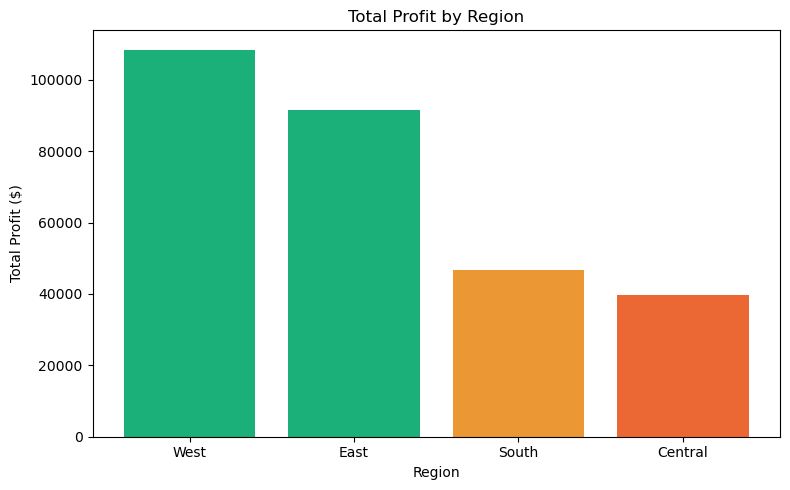

In [158]:
plt.figure(figsize=(8,5))
plt.bar(profit_by_region.index,profit_by_region.values,color=["#1baf7a", "#1baf7a", "#eb9834", "#eb6834"])

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit ($)")

plt.tight_layout()
plt.savefig("profit_by_region.png", dpi=150)
plt.show()

### This chart is highly meaningful because it compares the total profit generated by each region. It helps management identify the strongest and weakest performing regions.

### Key Insights – Total Profit by Region
* 🏆 West Region generated the highest profit (approximately $108K), making it the most profitable region.
* 🥈 East Region ranked second with around $91K in profit, showing strong business performance.
* 📉 South Region earned only about $47K, which is less than half of the West's profit.
* ⚠️ Central Region recorded the lowest profit (approximately $40K), indicating the weakest regional performance.
* 📊 There is a significant profit gap between the top-performing regions (West and East) and the lower-performing regions (South and Central).

### Business Recommendations
* ✅ Analyze the West Region's strategy (product mix, pricing, customer base, and sales approach) and replicate successful practices in other regions.
* 🎯 Investigate why the Central Region is underperforming. Factors such as higher discounts, lower sales, or operational costs may be affecting profitability.
* 📈 Increase marketing efforts and customer engagement in the South and Central regions to improve profit.
* 💰 Review discount policies in lower-performing regions to ensure profitability is not being reduced by excessive discounts.

### Slide Content (Professional)
### Key Insights
* 🏆 West is the most profitable region (~$108K).
* 🥈 East follows with ~$91K in total profit.
* 📉 South and Central generate significantly lower profits.
* ⚠️ Central is the least profitable region.
* 💡 Focus on improving profitability in South and Central while maintaining West's strong performance.

### Presentation Script (30 Seconds)

* "This chart compares total profit across the four regions. The West Region is the top performer, generating approximately $108,000 in profit, followed by the East Region with around $91,000. In contrast, the South and Central regions contribute significantly lower profits, with Central being the least profitable. This indicates that the company should analyze the success factors in the West and apply similar strategies in lower-performing regions while reviewing pricing and discount policies to improve profitability."

### Executive-Level Insight (Best for Interview/PPT)

* "Regional profitability is uneven. While the West and East regions drive most of the company's profit, the South and Central regions represent the greatest opportunity for improvement through targeted sales strategies, optimized pricing, and better operational efficiency."

* This insight demonstrates not only what the chart shows but also what business action should be taken, which is exactly what interviewers and stakeholders look for in a Data Analyst presentation.

## 5.2.3 Profit by Region and Category

In [159]:
profit = superstore_data.groupby(["Region","Category"])["Profit"].sum().reset_index()

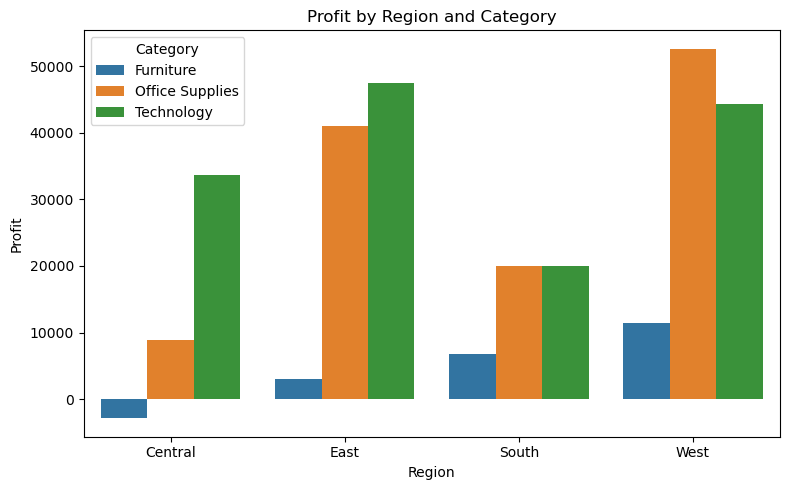

In [160]:
plt.figure(figsize=(8,5))
sns.barplot(data=profit,x="Region",y="Profit",hue="Category")

plt.title("Profit by Region and Category")
plt.tight_layout()
plt.savefig("Profit by Region and Category", dpi=150)
plt.show()


### This chart is very meaningful because it compares profit across regions and product categories, helping identify which category drives profit in each region and where improvements are needed.

### Key Insights – Profit by Region and Category
* 🏆 West Region generated the highest overall profit, driven mainly by Office Supplies and Technology.
* 📈 Technology is the most profitable category in the Central, East, and South regions, making it a key revenue driver.
* 📦 Office Supplies performed exceptionally well in the West Region, recording the highest profit among all region-category combinations.
* ⚠️ Furniture is the least profitable category across all regions and records a loss in the Central Region, indicating potential pricing or cost issues.
* 💡 East and West consistently outperform Central and South, suggesting stronger market demand or better sales performance in those regions.

### Business Recommendations
* ✅ Continue investing in Technology, as it consistently generates strong profits across most regions.
* 🎯 Replicate the successful Office Supplies strategy from the West Region in other regions.
* 🔍 Investigate why Furniture is unprofitable in the Central Region by reviewing discounts, costs, and product mix.
* 📈 Increase marketing and sales initiatives in the Central and South regions to improve overall profitability.

### Slide Content (Professional)
### Key Insights
* 🏆 West Region delivers the highest overall profit.
* 💻 Technology is the top-performing category in most regions.
* 📦 Office Supplies lead profitability in the West Region.
* ⚠️ Furniture underperforms and incurs a loss in the Central Region.
* 💡 Improve Furniture performance and replicate successful regional strategies.

### Presentation Script (40 Seconds)

* "This chart compares profit across different regions and product categories. The West Region is the strongest performer, with Office Supplies and Technology contributing the highest profits. Technology consistently performs well across most regions, highlighting its importance to the business. In contrast, Furniture is the weakest category and even records a loss in the Central Region. These findings suggest that the company should continue investing in high-performing categories while addressing the challenges affecting Furniture, particularly in the Central Region."

### Executive-Level Insight (Best for Interview/PPT)

* "Technology is the company's most consistent profit driver, while Furniture represents the biggest opportunity for improvement. Regional best practices from the West should be replicated, and the causes of Furniture losses in the Central Region should be investigated to improve overall profitability."

### One-Line Business Conclusion

* "Focus on expanding high-profit categories like Technology and Office Supplies while improving Furniture performance in underperforming regions to maximize overall business profitability."

# 5.3 Multivariat

## 5.3.1  Profit by Region and Category

In [161]:
pivot = superstore_data.pivot_table(values="Profit",index="Region",columns="Category",aggfunc="sum")
pivot

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.0494,8879.9799,33697.4320
East,3046.1658,41014.5791,47462.0351
South,6771.2061,19986.3928,19991.8314
West,11504.9503,52609.8490,44303.6496


In [162]:
lables = pivot.applymap(lambda x: f"${x/1000:.1f}k") # applymap is used for entaier DataFrame use to chanve value and operation perfrom 
labels

C:\Users\Tamilarasan\AppData\Local\Temp\ipykernel_17856\411565065.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  lables = pivot.applymap(lambda x: f"${x/1000:.1f}k") # applymap is used for entaier DataFrame use to chanve value and operation perfrom


Category,Furniture,Office Supplies,Technology
Region,,,
Central,$-2.9K,$8.9K,$33.7K
East,$3.0K,$41.0K,$47.5K
South,$6.8K,$20.0K,$20.0K
West,$11.5K,$52.6K,$44.3K


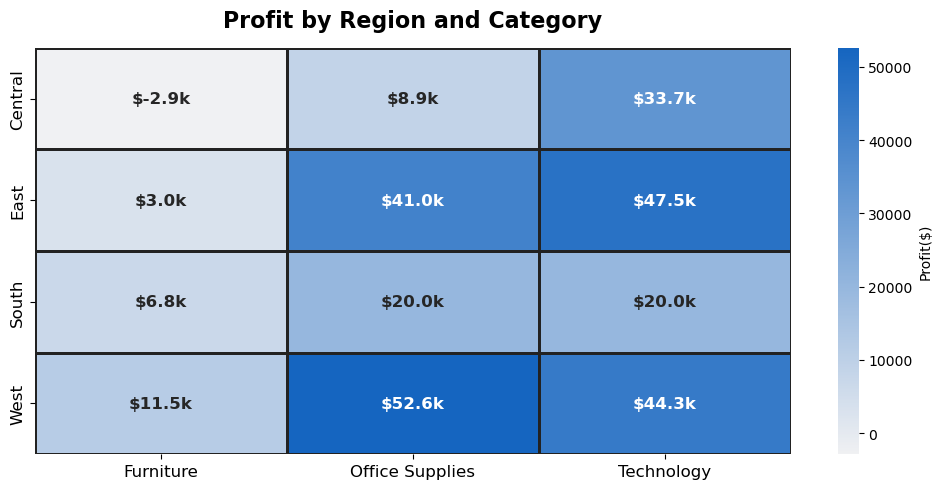

In [163]:
fig,ax = plt.subplots(figsize=(10,5))

sns.heatmap(
    pivot,
    annot=lables,
    fmt="",
    cmap=sns.light_palette("#1565C0",as_cmap=True),
    linewidths=2,
    linecolor="#222222",
    cbar_kws={"label":"Profit($)"},
    square=False,
    annot_kws={"fontsize":12,"fontweight":"bold"},
    ax=ax

)

ax.set_title("Profit by Region and Category",fontsize=16,color="black",weight="bold",pad=15)

ax.set_xlabel("")
ax.set_ylabel("")

ax.tick_params(axis="x",labelsize=12)
ax.tick_params(axis="y",labelsize=12)

plt.tight_layout()
plt.savefig("Profit by Region and Category_heatmap", dpi=150)
plt.show()



* Yes. This is an excellent business visualization because it shows profit by both Region and Category in a single view. It quickly highlights the strongest and weakest combinations.

### Key Insights – Profit by Region and Category
* 🏆 West – Office Supplies generated the highest profit($52.6K), making it the best-performing region-category combination. 

* 💻 Technology is a strong profit contributor across all regions, with the highest profit in the East ($47.5K) and strong performance in the West           ($44.3K). 

* 📦 Office Supplies consistently performs well in every region, particularly in the West ($52.6K) and East ($41.0K). 

* ⚠️ Furniture is the weakest category, and the Central Region records a loss (-$2.9K), indicating potential pricing, discount, or cost issues.

* 📈 West and East are the company's strongest regions, while Central has the weakest profitability and requires business attention.

### Business Recommendations
* ✅ Continue investing in Office Supplies and Technology, as they are the primary profit drivers.
* 🎯 Investigate the Furniture category in the Central Region to identify reasons for negative profit.
* 📊 Replicate the successful sales and pricing strategies used in the West Region across other regions.
* 💰 Review discount policies and operational costs in the Central Region to improve profitability.
### Slide Content (Professional)
### Key Insights

* 🏆 West–Office Supplies generated the highest profit ($52.6K).

* 💻 Technology delivers strong profits across all regions.

* 📦 Office Supplies consistently outperforms Furniture.

* ⚠️ Central–Furniture is the only region-category combination with a loss (-$2.9K).

* 💡 Focus on strengthening Furniture performance and improving profitability in the Central Region.
### Presentation Script (40 Seconds)

* "This heatmap compares profit across regions and product categories. The West Region's Office Supplies category generates the highest profit at $52.6K, while Technology consistently performs well across all regions. In contrast, Furniture is the weakest-performing category, with the Central Region recording a loss of $2.9K. These findings suggest that the company should continue investing in high-performing categories such as Office Supplies and Technology while investigating the causes of Furniture losses in the Central Region."

### Executive-Level Insight (Best for Interview/PPT)

* "Office Supplies and Technology are the company's primary profit drivers, while Furniture represents the largest improvement opportunity. Addressing Furniture's losses in the Central Region and replicating the West Region's successful strategies can significantly improve overall profitability."

### One-Line Business Conclusion

* "Maximize growth by expanding high-profit categories (Office Supplies and Technology) and implementing corrective actions for underperforming Furniture sales, especially in the Central Region."

# THE END!!!